<a href="https://colab.research.google.com/github/Shashi-kumar-g/machine-learning-26/blob/main/Day11_Student_shashi069.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Imports and labelled data

The supplied data dictionary describes `carat` as the strongest predictor, says price is right-skewed, and warns that zero dimensions are invalid. We keep `row_id` out of the training predictors; the training file provided here does not contain it.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, make_scorer

RANDOM_STATE = 42
train = pd.read_csv("diamonds_train - diamonds_train.csv")
X = train.drop(columns=["price"]).copy()
y = train["price"].astype(float)

print("Training rows/columns:", train.shape)
display(train.head())
print("scikit-learn:", sklearn.__version__)

Training rows/columns: (45849, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.51,Fair,F,SI1,65.2,57.0,1193,5.03,5.09,3.30
1,0.36,Ideal,G,VVS1,60.0,56.0,892,4.66,4.69,2.81
2,1.01,Very Good,F,SI1,62.8,60.0,5010,6.32,6.38,3.99
3,0.42,Ideal,E,VS2,61.7,56.0,1024,4.82,4.80,2.97
4,0.36,Ideal,H,SI1,61.4,56.0,684,4.56,4.59,2.81


scikit-learn: 1.6.1


## 2. Deterministic feature engineering

These features are calculated independently for each row. Invalid non-positive dimensions are marked missing. Imputation and categorical encoding are learned inside each fold through the pipelines below, preventing fold-to-fold preprocessing leakage.

In [2]:
def add_features(df):
    d = df.copy()
    for c in ["x", "y", "z"]:
        d.loc[d[c] <= 0, c] = np.nan
    d["volume"] = d["x"] * d["y"] * d["z"]
    d["carat_sq"] = d["carat"] ** 2
    d["carat_log1p"] = np.log1p(d["carat"].clip(lower=0))
    clarity_rank = {"I1":0, "SI2":1, "SI1":2, "VS2":3, "VS1":4, "VVS2":5, "VVS1":6, "IF":7}
    d["carat_x_clarity"] = d["carat"] * d["clarity"].map(clarity_rank).astype(float)
    return d

Xf = add_features(X)
categorical = ["cut", "color", "clarity"]
numeric = [c for c in Xf.columns if c not in categorical]

def make_preprocessor(scale_numeric=True):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)
    ])

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "rmse": make_scorer(lambda yt, yp: np.sqrt(mean_squared_error(yt, yp))),
    "mae": make_scorer(mean_absolute_error),
    "r2": make_scorer(r2_score)
}
print("Engineered features:", Xf.columns.tolist())

Engineered features: ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z', 'volume', 'carat_sq', 'carat_log1p', 'carat_x_clarity']


## 3. Compare the three allowed model families

The linear Ridge model is the baseline. KNN uses scaled numeric inputs and distance weighting. The decision tree can learn nonlinear thresholds and interactions. All three use the exact same 5-fold splitter and report RMSE, MAE, and R².

In [3]:
models = {
    "Ridge (raw target)": Pipeline([
        ("prep", make_preprocessor(scale_numeric=True)),
        ("model", Ridge(alpha=10.0))
    ]),
    "KNN (distance weights)": Pipeline([
        ("prep", make_preprocessor(scale_numeric=True)),
        ("model", KNeighborsRegressor(n_neighbors=12, weights="distance", n_jobs=-1))
    ]),
    "Decision Tree (depth=18, leaf=8)": Pipeline([
        ("prep", make_preprocessor(scale_numeric=False)),
        ("model", DecisionTreeRegressor(max_depth=18, min_samples_leaf=8, random_state=RANDOM_STATE))
    ])
}
rows = []
for name, model in models.items():
    start = time.time()
    scores = cross_validate(model, Xf, y, cv=kf, scoring=scoring, n_jobs=1)
    rows.append({
        "model": name,
        "cv_rmse": scores["test_rmse"].mean(),
        "cv_mae": scores["test_mae"].mean(),
        "cv_r2": scores["test_r2"].mean(),
        "seconds": time.time() - start
    })
comparison = pd.DataFrame(rows).sort_values("cv_rmse").reset_index(drop=True)
display(comparison)

,model,cv_rmse,cv_mae,cv_r2,seconds
0,"Decision Tree (depth=18, leaf=8)",659.202590,324.299241,0.972653,2.144253
1,KNN (distance weights),668.937663,349.523240,0.971865,12.120811
2,Ridge (raw target),1071.841774,573.617980,0.925254,2.091641


## 4. Tune the tree with a small, logged sprint

The experiment log is intentionally limited. We select by the lowest 5-fold CV RMSE, while retaining MAE and R² for context. These values are measured results from this notebook run, not hidden-set scores.

In [4]:
tree_candidates = [(14, 5), (16, 5), (18, 8), (20, 10), (None, 10)]
tuning_rows = []
for depth, leaf in tree_candidates:
    model = Pipeline([
        ("prep", make_preprocessor(scale_numeric=False)),
        ("model", DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=RANDOM_STATE))
    ])
    scores = cross_validate(model, Xf, y, cv=kf, scoring=scoring, n_jobs=1)
    tuning_rows.append({
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "cv_rmse": scores["test_rmse"].mean(),
        "cv_mae": scores["test_mae"].mean(),
        "cv_r2": scores["test_r2"].mean()
    })
tuning = pd.DataFrame(tuning_rows).sort_values("cv_rmse").reset_index(drop=True)
display(tuning)

experiment_log = pd.DataFrame([
    ["1", "Linear baseline", "Ridge alpha=10", comparison.loc[comparison.model=="Ridge (raw target)", "cv_rmse"].iloc[0], "No"],
    ["2", "KNN family", "k=12, weights=distance", comparison.loc[comparison.model=="KNN (distance weights)", "cv_rmse"].iloc[0], "No"],
    ["3", "Decision tree", "depth=18, leaf=8", comparison.loc[comparison.model=="Decision Tree (depth=18, leaf=8)", "cv_rmse"].iloc[0], "No"],
    ["4", "Tree tuning", "depth=20, leaf=10", tuning.iloc[0]["cv_rmse"], "Yes" if tuning.iloc[0]["max_depth"] == 20 else "Check best row"],
], columns=["#", "Idea", "Change made", "CV RMSE (USD)", "Kept?"])
display(experiment_log)

,max_depth,min_samples_leaf,cv_rmse,cv_mae,cv_r2
0,20.0,10,647.558876,320.541506,0.973618
1,NaN,10,647.606581,320.554032,0.973615
2,14.0,5,652.892291,324.257963,0.973205
3,18.0,8,659.202590,324.299241,0.972653
4,16.0,5,665.758153,327.826481,0.972130


,#,Idea,Change made,CV RMSE (USD),Kept?
0,1,Linear baseline,Ridge alpha=10,1071.841774,No
1,2,KNN family,"k=12, weights=distance",668.937663,No
2,3,Decision tree,"depth=18, leaf=8",659.202590,No
3,4,Tree tuning,"depth=20, leaf=10",647.558876,Yes


## 5. Training-only holdout diagnostics

This split is used only for error analysis and explanation; it is separate from the 5-fold CV comparison. The final contest model is refit on all labelled rows later.

{'holdout_RMSE_USD': 615.350083663276, 'holdout_MAE_USD': 314.44720637614375, 'holdout_R2': 0.9753451366634471}


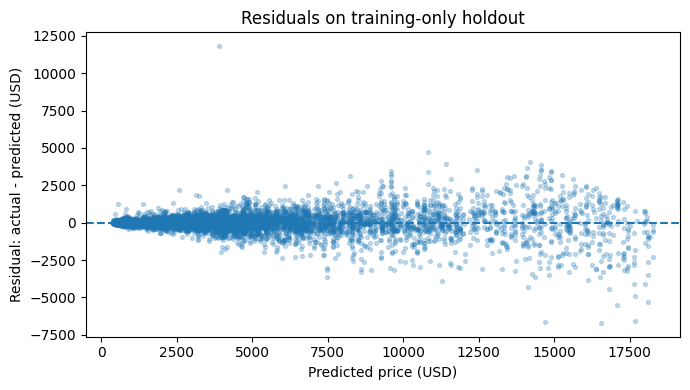

In [5]:
Xtr, Xval, ytr, yval = train_test_split(Xf, y, test_size=0.2, random_state=RANDOM_STATE)
diagnostic_model = Pipeline([
    ("prep", make_preprocessor(scale_numeric=False)),
    ("model", DecisionTreeRegressor(max_depth=20, min_samples_leaf=10, random_state=RANDOM_STATE))
])
diagnostic_model.fit(Xtr, ytr)
val_pred = diagnostic_model.predict(Xval)
residuals = yval - val_pred
print({
    "holdout_RMSE_USD": mean_squared_error(yval, val_pred) ** 0.5,
    "holdout_MAE_USD": mean_absolute_error(yval, val_pred),
    "holdout_R2": r2_score(yval, val_pred)
})

plt.figure(figsize=(7, 4))
plt.scatter(val_pred, residuals, s=8, alpha=0.25)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted price (USD)")
plt.ylabel("Residual: actual - predicted (USD)")
plt.title("Residuals on training-only holdout")
plt.tight_layout()
plt.show()

## 6. Explainability: permutation importance, PDP, and SHAP

Permutation importance measures how much holdout score worsens when one original input is shuffled. PDP shows the model's average response to carat. SHAP values describe how encoded feature values contribute to individual tree predictions. Treat all these as explanations of model behaviour, not causal claims.

,feature,importance
9,volume,1916.125725
7,y,1502.235455
12,carat_x_clarity,1479.173717
2,color,711.620316
10,carat_sq,72.320813
8,z,54.457235
6,x,25.319847
0,carat,21.671920
11,carat_log1p,20.063731
1,cut,15.619454


<Figure size 700x400 with 0 Axes>

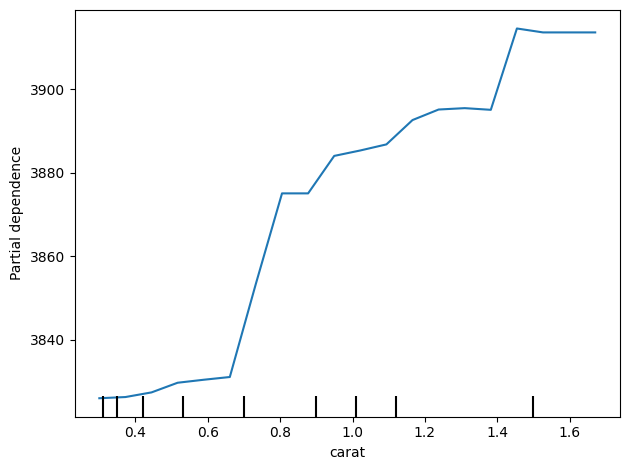

In [6]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

perm = permutation_importance(
    diagnostic_model, Xval, yval, n_repeats=3, random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error", n_jobs=1
)
importance = pd.DataFrame({"feature": Xval.columns, "importance": perm.importances_mean})
importance = importance.sort_values("importance", ascending=False)
display(importance.head(12))

plt.figure(figsize=(7, 4))
PartialDependenceDisplay.from_estimator(diagnostic_model, Xval, ["carat"], grid_resolution=20)
plt.tight_layout()
plt.show()

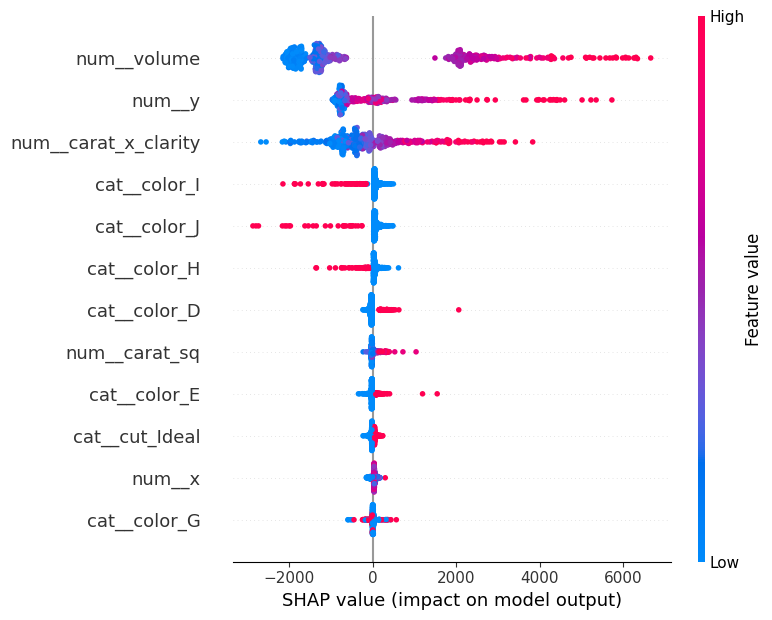

In [7]:
# Optional SHAP summary. If SHAP is unavailable, install it in the environment and rerun this cell.
try:
    import shap
    transformed = diagnostic_model.named_steps["prep"].transform(Xval.iloc[:500])
    transformed_names = diagnostic_model.named_steps["prep"].get_feature_names_out()
    explainer = shap.TreeExplainer(diagnostic_model.named_steps["model"])
    shap_values = explainer.shap_values(transformed)
    shap.summary_plot(shap_values, transformed, feature_names=transformed_names, max_display=12)
except ImportError:
    print("SHAP is not installed. In Colab, run: %pip install shap")

## 7. Freeze the selected model and create the submission

**The hidden file is opened only in this final section.** The selected parameters are `max_depth=20`, `min_samples_leaf=10`. The final model is fitted on all labelled rows. The output must have exactly `row_id, price`, preserve hidden row order, contain no missing predictions, and predict positive USD prices.

In [8]:
best_pipeline = Pipeline([
    ("prep", make_preprocessor(scale_numeric=False)),
    ("model", DecisionTreeRegressor(max_depth=20, min_samples_leaf=10, random_state=RANDOM_STATE))
])
start = time.time()
best_pipeline.fit(Xf, y)
fit_seconds = time.time() - start

# Load the hidden features only after all model choices and diagnostics are complete.
hidden = pd.read_csv("diamonds_hidden_test_features - diamonds_hidden_test_features.csv")
hidden_features = add_features(hidden.drop(columns=["row_id"]))
predictions = np.maximum(best_pipeline.predict(hidden_features), 1.0)
submission = pd.DataFrame({"row_id": hidden["row_id"], "price": predictions})
assert submission.shape[0] == len(hidden)
assert submission.columns.tolist() == ["row_id", "price"]
assert submission["price"].notna().all()
assert (submission["price"] > 0).all()
assert submission["row_id"].equals(hidden["row_id"])
submission.to_csv("submission.csv", index=False)

best_cv = tuning.iloc[0]
leaderboard_row = pd.DataFrame([{
    "student": "Student",
    "model": "Decision Tree (max_depth=20, min_samples_leaf=10)",
    "cv_rmse": best_cv["cv_rmse"],
    "cv_mae": best_cv["cv_mae"],
    "fit_seconds": round(fit_seconds, 3),
    "n_features": Xf.shape[1]
}])
leaderboard_row.to_csv("leaderboard_row.csv", index=False)
display(submission.head())
display(leaderboard_row)
print("Submission shape:", submission.shape, "| prediction range:", predictions.min(), "to", predictions.max())

,row_id,price
0,0,4984.666667
1,1,914.212121
2,2,4861.559322
3,3,803.636364
4,4,590.315789


,student,model,cv_rmse,cv_mae,fit_seconds,n_features
0,Student,"Decision Tree (max_depth=20, min_samples_leaf=10)",647.558876,320.541506,0.502,13


Submission shape: (8091, 2) | prediction range: 367.8 to 18231.58823529412
